Using Colab cache for faster access to the 'suicide-watch' dataset.
[1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0]


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

...

Epoch: 17. Loss: 0.0179


100%|██████████| 2176/2176 [01:07<00:00, 32.19it/s]


Epoch: 18. Loss: 0.0168


100%|██████████| 2176/2176 [01:07<00:00, 32.18it/s]


Epoch: 19. Loss: 0.0152


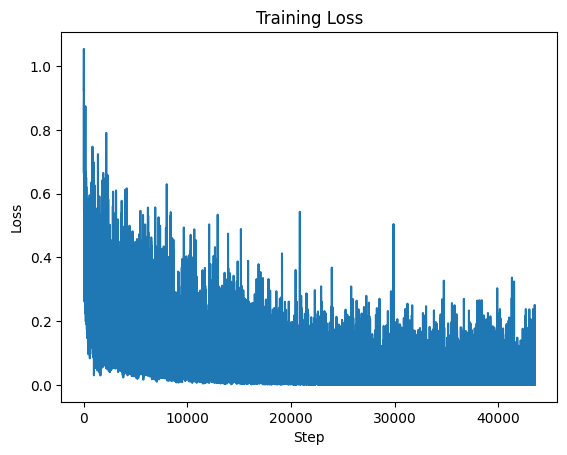

100%|██████████| 63/63 [00:01<00:00, 36.55it/s]


Time: 1.7256916779997482
Accuracy: 0.9470
Precision: 0.9532710280373832
Recall: 0.9376915219611849
F1: 0.945417095777549
ROC-AUC: 0.989162220539258


In [ ]:
import pandas as pd
import torch
from torch import nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import kagglehub
import matplotlib.pyplot as plt
from tqdm import tqdm
import kagglehub
import random
import os
import numpy as np
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset_path = kagglehub.dataset_download("nikhileswarkomati/suicide-watch")
data = pd.read_csv(dataset_path + "/Suicide_Detection.csv").sample(frac=0.375, random_state=0)
data["label"] = data["class"].astype("category").cat.codes

texts = data["text"].astype(str).tolist()
labels = data["label"].tolist()
print(labels[0:20])

from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

vocab_size = tokenizer.vocab_size
pad_idx = tokenizer.pad_token_id

class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = tokenizer(
            self.texts[index],
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        input_ids = encoding["input_ids"].squeeze(0)

        label_tensor = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return input_ids, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return input_ids, labels

dataset = TextDataset(texts, labels)
train_size = int(0.8 * len(dataset))
train_dataset = torch.utils.data.Subset(dataset, range(0, train_size))
eval_dataset  = torch.utils.data.Subset(dataset, range(train_size, train_size + 2000))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)
eval_loader  = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class CNN(nn.Module):
    def __init__(self, vocab_size, emb_dim, num_filters=128, num_classes=2, dropout=0.5, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)

        self.conv3 = nn.Conv1d(emb_dim, num_filters, 3)
        self.conv4 = nn.Conv1d(emb_dim, num_filters, 4)
        self.conv5 = nn.Conv1d(emb_dim, num_filters, 5)

        self.pool = nn.AdaptiveMaxPool1d(1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(num_filters * 3, num_classes)

    def forward(self, input_ids):
        x = self.embedding(input_ids)
        x = x.transpose(1, 2)

        h3 = self.relu(self.conv3(x))
        h4 = self.relu(self.conv4(x))
        h5 = self.relu(self.conv5(x))

        p3 = self.pool(h3).squeeze(2)
        p4 = self.pool(h4).squeeze(2)
        p5 = self.pool(h5).squeeze(2)

        x = torch.cat([p3, p4, p5], dim=1)
        x = self.dropout(x)
        return self.classifier(x)

model = CNN(vocab_size=vocab_size, emb_dim=768, pad_idx=pad_idx).to(device)
print(sum(p.numel() for p in model.parameters()))
optimizer = optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss()
losses = []

for epoch in range(20):
    model.train()
    total_loss = 0
    for batch_x, batch_y in tqdm(train_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        loss = loss_fn(logits, batch_y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        total_loss += loss.item()
    print(f"Epoch: {epoch}. Loss: {(total_loss / len(train_loader)):.4f}")

plt.plot(losses)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")
torch.save(model.state_dict(), "cnn_suicide_classifier.pt")


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import kagglehub
import random
import os
import numpy as np
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset_path = kagglehub.dataset_download("rvarun11/suicidal-ideation-reddit-dataset")
data = pd.read_csv(dataset_path + "/suicidal_ideation_reddit_annotated.csv")

data["text"] = data["usertext"].astype(str)
texts = data["text"].tolist()
labels = data["label"].astype(int).tolist()

indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]

from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

vocab_size = tokenizer.vocab_size
pad_idx = tokenizer.pad_token_id

class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = tokenizer(
            self.texts[index],
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        input_ids = encoding["input_ids"].squeeze(0)

        label_tensor = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return input_ids, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return input_ids, labels

eval_dataset = TextDataset(texts, labels, max_length=128)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class CNN(nn.Module):
    def __init__(self, vocab_size, emb_dim, num_filters=128, num_classes=2, dropout=0.5, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.conv3 = nn.Conv1d(emb_dim, num_filters, 3)
        self.conv4 = nn.Conv1d(emb_dim, num_filters, 4)
        self.conv5 = nn.Conv1d(emb_dim, num_filters, 5)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(num_filters * 3, num_classes)

    def forward(self, input_ids):
        x = self.embedding(input_ids)
        x = x.transpose(1, 2)
        h3 = self.relu(self.conv3(x))
        h4 = self.relu(self.conv4(x))
        h5 = self.relu(self.conv5(x))
        p3 = self.pool(h3).squeeze(2)
        p4 = self.pool(h4).squeeze(2)
        p5 = self.pool(h5).squeeze(2)
        x = torch.cat([p3, p4, p5], dim=1)
        x = self.dropout(x)
        return self.classifier(x)

model = CNN(vocab_size=vocab_size, emb_dim=768, pad_idx=pad_idx).to(device)
model.load_state_dict(torch.load("cnn_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

100%|██████████| 3.79M/3.79M [00:01<00:00, 2.94MB/s]

Extracting files...



100%|██████████| 63/63 [00:02<00:00, 30.98it/s]

Time: 2.0361277379997773
Accuracy: 0.8485
Precision: 0.8192668371696504
Recall: 0.9134980988593155
F1: 0.8638202247191011
ROC-AUC: 0.9129646564309893


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import kagglehub
import random
import os
import numpy as np
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mapping = {
    "non-suicide": 0,
    "suicide": 1
}
dataset_path = kagglehub.dataset_download("neelakshigupta/suicide-detection")
data = pd.read_csv(dataset_path + "/file1.csv")
data["text"] = data["text"]
data["Suicide"] = data["class"].map(mapping)
data = data.dropna(subset = ["text", "class"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]

from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

vocab_size = tokenizer.vocab_size
pad_idx = tokenizer.pad_token_id

class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = tokenizer(
            self.texts[index],
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        input_ids = encoding["input_ids"].squeeze(0)

        label_tensor = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return input_ids, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return input_ids, labels

eval_dataset = TextDataset(texts, labels, max_length=128)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class CNN(nn.Module):
    def __init__(self, vocab_size, emb_dim, num_filters=128, num_classes=2, dropout=0.5, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.conv3 = nn.Conv1d(emb_dim, num_filters, 3)
        self.conv4 = nn.Conv1d(emb_dim, num_filters, 4)
        self.conv5 = nn.Conv1d(emb_dim, num_filters, 5)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(num_filters * 3, num_classes)

    def forward(self, input_ids):
        x = self.embedding(input_ids)
        x = x.transpose(1, 2)
        h3 = self.relu(self.conv3(x))
        h4 = self.relu(self.conv4(x))
        h5 = self.relu(self.conv5(x))
        p3 = self.pool(h3).squeeze(2)
        p4 = self.pool(h4).squeeze(2)
        p5 = self.pool(h5).squeeze(2)
        x = torch.cat([p3, p4, p5], dim=1)
        x = self.dropout(x)
        return self.classifier(x)

model = CNN(vocab_size=vocab_size, emb_dim=768, pad_idx=pad_idx).to(device)
model.load_state_dict(torch.load("cnn_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

100%|██████████| 1.45M/1.45M [00:01<00:00, 1.37MB/s]

Extracting files...



100%|██████████| 63/63 [00:01<00:00, 49.78it/s]

Time: 1.2681988319991433
Accuracy: 0.8950
Precision: 0.863593603010348
Recall: 0.9338758901322483
F1: 0.8973607038123167
ROC-AUC: 0.9576002464712302


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm
import kagglehub
import random
import os
import numpy as np
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mapping = {
    "Not Suicide post": 0,
    "Potential Suicide post ": 1
}
dataset_path = kagglehub.dataset_download("aunanya875/suicidal-tweet-detection-dataset")
data = pd.read_csv(dataset_path + "/Suicide_Ideation_Dataset(Twitter-based).csv")
data["text"] = data["Tweet"]
data["Suicide"] = data["Suicide"].map(mapping)
data = data.dropna(subset=["Tweet", "Suicide"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

vocab_size = tokenizer.vocab_size
pad_idx = tokenizer.pad_token_id

class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = tokenizer(
            self.texts[index],
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        input_ids = encoding["input_ids"].squeeze(0)

        label_tensor = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return input_ids, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return input_ids, labels

eval_dataset = TextDataset(texts, labels, max_length=128)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class CNN(nn.Module):
    def __init__(self, vocab_size, emb_dim, num_filters=128, num_classes=2, dropout=0.5, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.conv3 = nn.Conv1d(emb_dim, num_filters, 3)
        self.conv4 = nn.Conv1d(emb_dim, num_filters, 4)
        self.conv5 = nn.Conv1d(emb_dim, num_filters, 5)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(num_filters * 3, num_classes)

    def forward(self, input_ids):
        x = self.embedding(input_ids)
        x = x.transpose(1, 2)
        h3 = self.relu(self.conv3(x))
        h4 = self.relu(self.conv4(x))
        h5 = self.relu(self.conv5(x))
        p3 = self.pool(h3).squeeze(2)
        p4 = self.pool(h4).squeeze(2)
        p5 = self.pool(h5).squeeze(2)
        x = torch.cat([p3, p4, p5], dim=1)
        x = self.dropout(x)
        return self.classifier(x)

model = CNN(vocab_size=vocab_size, emb_dim=768, pad_idx=pad_idx).to(device)
model.load_state_dict(torch.load("cnn_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")


100%|██████████| 88.3k/88.3k [00:00<00:00, 372kB/s]

Extracting files...



100%|██████████| 56/56 [00:00<00:00, 74.22it/s]

Time: 0.7566840689996752
Accuracy: 0.6711
Precision: 0.5983606557377049
Recall: 0.3323216995447648
F1: 0.4273170731707317
ROC-AUC: 0.6096351380125439


# CNN + MLP

Using Colab cache for faster access to the 'suicide-watch' dataset.
[1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 0]


  5%|▌         | 1/20 [01:01<19:30, 61.61s/it]

Epoch: 0. Loss: 0.3984


 10%|█         | 2/20 [02:02<18:26, 61.45s/it]

Epoch: 1. Loss: 0.2503


...

Epoch: 17. Loss: 0.0260


 95%|█████████▌| 19/20 [19:29<01:01, 61.03s/it]

Epoch: 18. Loss: 0.0235


100%|██████████| 20/20 [20:31<00:00, 61.55s/it]

Epoch: 19. Loss: 0.0226


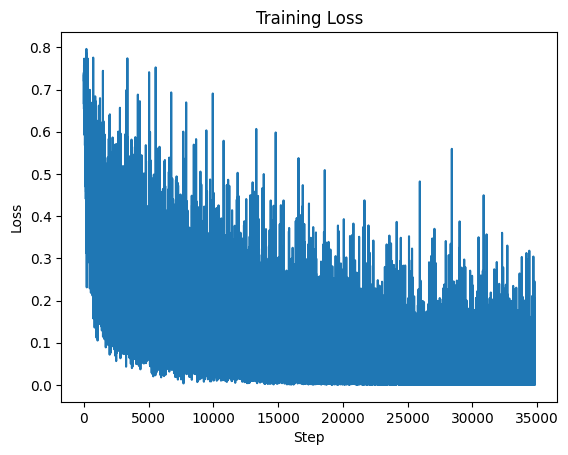

100%|██████████| 63/63 [00:02<00:00, 31.32it/s]


Time: 2.01373210300153
Accuracy: 0.9510
Precision: 0.9445026178010472
Recall: 0.9524815205913411
F1: 0.9484752891692955
ROC-AUC: 0.9873825576043105


In [ ]:
import pandas as pd
import torch
from torch import nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, Subset
from transformers import AutoTokenizer, AutoModel
import kagglehub
import matplotlib.pyplot as plt
from tqdm import tqdm
import kagglehub
import random
import os
import numpy as np
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset_path = kagglehub.dataset_download("nikhileswarkomati/suicide-watch")
data = pd.read_csv(dataset_path + "/Suicide_Detection.csv").sample(frac=0.3, random_state=0)
data["label"] = data["class"].astype("category").cat.codes

texts = data["text"].astype(str).tolist()
labels = data["label"].tolist()
print(labels[0:20])
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

vocab_size = tokenizer.vocab_size
pad_idx = tokenizer.pad_token_id

class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = tokenizer(
            self.texts[index],
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        input_ids = encoding["input_ids"].squeeze(0)

        label_tensor = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return input_ids, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return input_ids, labels

dataset = TextDataset(texts, labels)
train_size = int(0.8 * len(dataset))
train_dataset = Subset(dataset, range(0, train_size))
eval_dataset  = Subset(dataset, range(train_size, train_size + 2000))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, collate_fn=collate_fn)
eval_loader  = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)
class CNN_MLP(nn.Module):
    def __init__(self, vocab_size, emb_dim, num_filters=128, num_classes=2, dropout=0.5, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.conv3 = nn.Conv1d(emb_dim, num_filters, 3)
        self.conv4 = nn.Conv1d(emb_dim, num_filters, 4)
        self.conv5 = nn.Conv1d(emb_dim, num_filters, 5)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Sequential(
            nn.Linear(num_filters * 3, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )
    def forward(self, input_ids):
        x = self.embedding(input_ids)
        x = x.transpose(1, 2)
        h3 = self.relu(self.conv3(x))
        h4 = self.relu(self.conv4(x))
        h5 = self.relu(self.conv5(x))
        p3 = self.pool(h3).squeeze(2)
        p4 = self.pool(h4).squeeze(2)
        p5 = self.pool(h5).squeeze(2)
        x = torch.cat([p3, p4, p5], dim=1)
        x = self.dropout(x)
        return self.classifier(x)

model = CNN_MLP(vocab_size=vocab_size, emb_dim=768, pad_idx=0).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)
loss_fn = nn.CrossEntropyLoss()
losses = []

for epoch in tqdm(range(20)):
    model.train()
    total_loss = 0
    for batch_x, batch_y in train_loader:
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        loss = loss_fn(logits, batch_y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
        total_loss += loss.item()
    print(f"Epoch: {epoch}. Loss: {(total_loss / len(train_loader)):.4f}")

plt.plot(losses)
plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")
torch.save(model.state_dict(), "cnn_mlp_suicide_classifier.pt")


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
from tqdm import tqdm
import kagglehub
import random
import os
import numpy as np
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset_path = kagglehub.dataset_download("rvarun11/suicidal-ideation-reddit-dataset")
data = pd.read_csv(dataset_path + "/suicidal_ideation_reddit_annotated.csv")

data["text"] = data["usertext"].astype(str)
texts = data["text"].tolist()
labels = data["label"].astype(int).tolist()

indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

vocab_size = tokenizer.vocab_size
pad_idx = tokenizer.pad_token_id

class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = tokenizer(
            self.texts[index],
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        input_ids = encoding["input_ids"].squeeze(0)

        label_tensor = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return input_ids, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return input_ids, labels

eval_dataset = TextDataset(texts, labels, max_length=128)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class CNN_MLP(nn.Module):
    def __init__(self, vocab_size, emb_dim, num_filters=128, num_classes=2, dropout=0.5, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.conv3 = nn.Conv1d(emb_dim, num_filters, 3)
        self.conv4 = nn.Conv1d(emb_dim, num_filters, 4)
        self.conv5 = nn.Conv1d(emb_dim, num_filters, 5)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Sequential(
            nn.Linear(num_filters * 3, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )
    def forward(self, input_ids):
        x = self.embedding(input_ids)
        x = x.transpose(1, 2)
        h3 = self.relu(self.conv3(x))
        h4 = self.relu(self.conv4(x))
        h5 = self.relu(self.conv5(x))
        p3 = self.pool(h3).squeeze(2)
        p4 = self.pool(h4).squeeze(2)
        p5 = self.pool(h5).squeeze(2)
        x = torch.cat([p3, p4, p5], dim=1)
        x = self.dropout(x)
        return self.classifier(x)

model = CNN_MLP(vocab_size=vocab_size, emb_dim=768, pad_idx=0).to(device)

model.load_state_dict(torch.load("cnn_mlp_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

Using Colab cache for faster access to the 'suicidal-ideation-reddit-dataset' dataset.


100%|██████████| 63/63 [00:02<00:00, 26.58it/s]

Time: 2.372767639999438
Accuracy: 0.8290
Precision: 0.802901023890785
Recall: 0.8944866920152091
F1: 0.8462230215827338
ROC-AUC: 0.9050407301342832


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
from tqdm import tqdm
import kagglehub
import random
import os
import numpy as np
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
mapping = {
    "non-suicide": 0,
    "suicide": 1
}
dataset_path = kagglehub.dataset_download("neelakshigupta/suicide-detection")
data = pd.read_csv(dataset_path + "/file1.csv")
data["text"] = data["text"]
data["Suicide"] = data["class"].map(mapping)
data = data.dropna(subset = ["text", "class"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

vocab_size = tokenizer.vocab_size
pad_idx = tokenizer.pad_token_id

class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = tokenizer(
            self.texts[index],
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        input_ids = encoding["input_ids"].squeeze(0)

        label_tensor = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return input_ids, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return input_ids, labels

eval_dataset = TextDataset(texts, labels, max_length=128)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)
class CNN_MLP(nn.Module):
    def __init__(self, vocab_size, emb_dim, num_filters=128, num_classes=2, dropout=0.5, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.conv3 = nn.Conv1d(emb_dim, num_filters, 3)
        self.conv4 = nn.Conv1d(emb_dim, num_filters, 4)
        self.conv5 = nn.Conv1d(emb_dim, num_filters, 5)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Sequential(
            nn.Linear(num_filters * 3, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )
    def forward(self, input_ids):
        x = self.embedding(input_ids)
        x = x.transpose(1, 2)
        h3 = self.relu(self.conv3(x))
        h4 = self.relu(self.conv4(x))
        h5 = self.relu(self.conv5(x))
        p3 = self.pool(h3).squeeze(2)
        p4 = self.pool(h4).squeeze(2)
        p5 = self.pool(h5).squeeze(2)
        x = torch.cat([p3, p4, p5], dim=1)
        x = self.dropout(x)
        return self.classifier(x)
model = CNN_MLP(vocab_size=vocab_size, emb_dim=768, pad_idx=0).to(device)
model.load_state_dict(torch.load("cnn_mlp_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

Using Colab cache for faster access to the 'suicide-detection' dataset.


100%|██████████| 63/63 [00:01<00:00, 45.74it/s]

Time: 1.380103464000058
Accuracy: 0.8780
Precision: 0.831390134529148
Recall: 0.943031536113937
F1: 0.8836987607244995
ROC-AUC: 0.9470471966398288


In [ ]:
import pandas as pd
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer
from tqdm import tqdm
import random
import os
import numpy as np
SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

os.environ["PYTHONHASHSEED"] = str(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import kagglehub
mapping = {
    "Not Suicide post": 0,
    "Potential Suicide post ": 1
}
dataset_path = kagglehub.dataset_download("aunanya875/suicidal-tweet-detection-dataset")
data = pd.read_csv(dataset_path + "/Suicide_Ideation_Dataset(Twitter-based).csv")
data["text"] = data["Tweet"]
data["Suicide"] = data["Suicide"].map(mapping)
data = data.dropna(subset=["Tweet", "Suicide"])
data["Suicide"] = data["Suicide"].astype(int)
texts = data["text"].tolist()
labels = data["Suicide"].tolist()
indices = torch.randperm(len(texts))[:2000].tolist()
texts  = [texts[i] for i in indices]
labels = [labels[i] for i in indices]
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained("distilbert-base-uncased")

vocab_size = tokenizer.vocab_size
pad_idx = tokenizer.pad_token_id

class TextDataset(Dataset):
    def __init__(self, texts, labels, max_length=128):
        self.texts = texts
        self.labels = labels
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, index):
        encoding = tokenizer(
            self.texts[index],
            max_length=self.max_length,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )

        input_ids = encoding["input_ids"].squeeze(0)

        label_tensor = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return input_ids, label_tensor

def collate_fn(batch):
    input_ids = torch.stack([item[0] for item in batch])
    labels = torch.stack([item[1] for item in batch])
    return input_ids, labels

eval_dataset = TextDataset(texts, labels, max_length=128)
eval_loader = DataLoader(eval_dataset, batch_size=32, shuffle=False, collate_fn=collate_fn)

class CNN_MLP(nn.Module):
    def __init__(self, vocab_size, emb_dim, num_filters=128, num_classes=2, dropout=0.5, pad_idx=0):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
        self.conv3 = nn.Conv1d(emb_dim, num_filters, 3)
        self.conv4 = nn.Conv1d(emb_dim, num_filters, 4)
        self.conv5 = nn.Conv1d(emb_dim, num_filters, 5)
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Sequential(
            nn.Linear(num_filters * 3, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )
    def forward(self, input_ids):
        x = self.embedding(input_ids)
        x = x.transpose(1, 2)
        h3 = self.relu(self.conv3(x))
        h4 = self.relu(self.conv4(x))
        h5 = self.relu(self.conv5(x))
        p3 = self.pool(h3).squeeze(2)
        p4 = self.pool(h4).squeeze(2)
        p5 = self.pool(h5).squeeze(2)
        x = torch.cat([p3, p4, p5], dim=1)
        x = self.dropout(x)
        return self.classifier(x)
model = CNN_MLP(vocab_size=vocab_size, emb_dim=768, pad_idx=0).to(device)
model.load_state_dict(torch.load("cnn_mlp_suicide_classifier.pt", map_location=device))
model.eval()
total = 0
correct = 0
preds = []
probs = []
final_labels = []
import time
t0 = time.perf_counter()
import numpy as np
with torch.no_grad():
    for batch_x, batch_y in tqdm(eval_loader):
        batch_x = batch_x.to(device)
        batch_y = batch_y.to(device)
        logits = model(batch_x)
        predictions = logits.argmax(dim=1)
        probabilities = torch.softmax(logits, dim=1)[:, 1]
        preds.append(predictions.cpu().numpy())
        probs.append(probabilities.cpu().numpy())
        final_labels.append(batch_y.cpu().numpy())
        total += len(batch_y)
        correct += (predictions == batch_y).sum().item()
t1 = time.perf_counter()
print(f"Time: {t1-t0}")
preds = np.concatenate(preds)
probs = np.concatenate(probs)
final_labels = np.concatenate(final_labels)
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
print(f"Accuracy: {correct/total:.4f}")
print(f"Precision: {precision_score(final_labels, preds)}")
print(f"Recall: {recall_score(final_labels, preds)}")
print(f"F1: {f1_score(final_labels, preds)}")
print(f"ROC-AUC: {roc_auc_score(final_labels, probs)}")

Using Colab cache for faster access to the 'suicidal-tweet-detection-dataset' dataset.


100%|██████████| 56/56 [00:00<00:00, 70.47it/s]

Time: 0.7970355340003152
Accuracy: 0.6768
Precision: 0.6102150537634409
Recall: 0.34446130500758726
F1: 0.44034917555771097
ROC-AUC: 0.632635431799621
